# Practical 9: End-to-End Data Pipelines: E-Commerce ETL with Historical and New Data

**Name:** Vedant Vinod Rakshe

**Aim:** To build an end-to-end pipeline from CSV through Python/Pandas, data cleaning and a SQL database to a report; to build an ETL pipeline for an e-commerce dataset containing customers, orders, products and payments; and to design a data pipeline that handles both historical and newly arriving data.

## Task 1: End-to-End Pipeline: CSV -> Pandas -> Data Cleaning -> SQL Database -> Report

Name: Vedant Vinod Rakshe
Rows extracted: 10
Invalid rows removed: 2 | duplicates removed: 1

REVENUE BY REGION
 region  orders  revenue
  West       3   117000
 South       1    25000
 North       2    12500
  East       1      400

REVENUE BY MONTH
   month  revenue
2026-01   116000
2026-02     9000
2026-03    29900


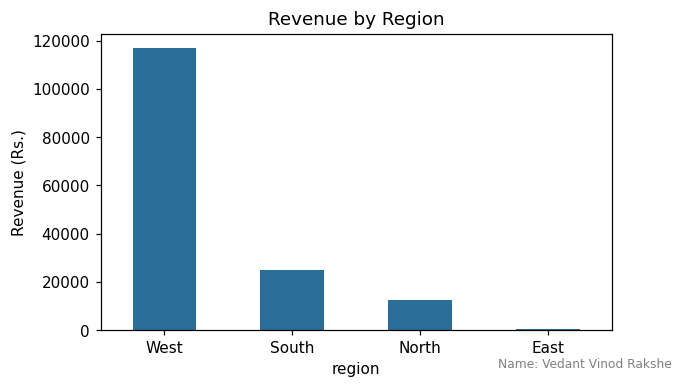

In [1]:
# Name: Vedant Vinod Rakshe
# PIPELINE 1 : CSV -> Python/Pandas -> Data Cleaning -> SQL Database -> Report
print("Name: Vedant Vinod Rakshe")
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

# ---- Source file (contains duplicates, a missing value and a negative price)
with open("sales_raw.csv", "w") as f:
    f.write("order_id,date,region,product,units,unit_price\n")
    for line in ["1,2026-01-05,west,Laptop,2,55000", "2,2026-01-06,WEST,Mouse,5,500",
                 "3,2026-01-08,North,Chair,1,3500", "4,2026-02-02,north ,Desk,1,9000",
                 "4,2026-02-02,north ,Desk,1,9000", "5,2026-02-10,South,Notebook,,60",
                 "6,2026-02-14,East,Monitor,2,-12000", "7,2026-03-01,South,Sofa,1,25000",
                 "8,2026-03-04,East,Pen Pack,10,40", "9,2026-03-09,West,Keyboard,3,1500"]:
        f.write(line + "\n")

# ---- 1. EXTRACT
raw = pd.read_csv("sales_raw.csv")
print("Rows extracted:", len(raw))

# ---- 2. CLEAN
df = raw.copy()
df["region"] = df["region"].str.strip().str.title()
df["date"] = pd.to_datetime(df["date"])
df = df.drop_duplicates()
bad = df["units"].isna() | (df["units"] <= 0) | (df["unit_price"] <= 0)
dups = len(raw) - len(raw.drop_duplicates())
print("Invalid rows removed:", int(bad.sum()), "| duplicates removed:", dups)
df = df[~bad].copy()
df["units"] = df["units"].astype(int)
df["revenue"] = df["units"] * df["unit_price"]
df["month"] = df["date"].dt.strftime("%Y-%m")

# ---- 3. LOAD into the SQL database
conn1 = sqlite3.connect("pipeline1.db")
df.to_sql("sales", conn1, if_exists="replace", index=False)

# ---- 4. REPORT using SQL
by_region = pd.read_sql("""SELECT region, COUNT(*) AS orders, SUM(revenue) AS revenue
                           FROM sales GROUP BY region ORDER BY revenue DESC""", conn1)
by_month = pd.read_sql("SELECT month, SUM(revenue) AS revenue FROM sales GROUP BY month", conn1)
print("\nREVENUE BY REGION\n", by_region.to_string(index=False))
print("\nREVENUE BY MONTH\n", by_month.to_string(index=False))
by_region.to_csv("sales_report.csv", index=False)

by_region.plot(kind="bar", x="region", y="revenue", legend=False, color="#2a6f97", figsize=(6, 3.5))
plt.title("Revenue by Region"); plt.ylabel("Revenue (Rs.)"); plt.xticks(rotation=0)
plt.gcf().text(0.99, 0.005, "Name: Vedant Vinod Rakshe", ha="right", va="bottom", fontsize=8, color="gray")
plt.savefig("p9_region_revenue.png", dpi=110, bbox_inches="tight")
plt.show()

## Task 2: E-Commerce ETL - Extract and Clean Customers, Products, Orders and Payments

The raw data contains duplicate customers, an invalid e-mail, an order for an unknown customer, an order for an unknown product, an order with quantity zero, a duplicate payment and a payment for a rejected order. Each cleaning function removes or fixes these problems and bad orders are kept in a rejected list with the reason.

In [2]:
# PIPELINE 2 : E-commerce ETL (customers, products, orders, payments)
print("Name: Vedant Vinod Rakshe")
import sqlite3

# ---- Raw extracts (as received from the source systems)
customers_raw = pd.DataFrame({
    "customer_id": ["C01", "C02", "C03", "C04", "C05", "C02", "C06"],
    "name": ["amit shah ", "Riya Patil", "neha rao", "Karan Jain", "Sana Khan", "Riya Patil", "Dev Mehta"],
    "email": [" AMIT@MAIL.COM ", "riya@mail.com", "Neha@Mail.com", "karan@mail.com",
              "sana@mail", "riya@mail.com", "dev@mail.com"],
    "city": ["Mumbai", "Pune", "Delhi", "Nashik", "Pune", "Pune", "Surat"]})
products_raw = pd.DataFrame({
    "product_id": ["P1", "P2", "P3", "P4", "P5"],
    "product_name": ["Laptop", "Mouse", "Chair", "Notebook", "Headphones"],
    "category": ["Electronics", "Electronics", "Furniture", "Stationery", "Electronics"],
    "price": [55000, 500, 3500, 60, 2500]})
orders_raw = pd.DataFrame({
    "order_id": [5001, 5002, 5003, 5004, 5005, 5006, 5007, 5008, 5009, 5010, 5011, 5012],
    "customer_id": ["C01", "C02", "C03", "C04", "C05", "C01", "C09", "C06", "C02", "C03", "C06", "C04"],
    "product_id": ["P1", "P2", "P3", "P4", "P5", "P2", "P3", "P9", "P4", "P5", "P1", "P3"],
    "quantity": [1, 2, 1, 10, 1, 3, 1, 1, 0, 2, 1, 2],
    "order_date": ["2026-01-03", "2026-01-05", "2026-01-07", "2026-01-10", "2026-01-12", "2026-01-15",
                   "2026-01-16", "2026-01-18", "2026-01-20", "2026-01-22", "2026-01-25", "2026-01-28"],
    "status": ["delivered", "DELIVERED", "shipped", "shipped", "delivered", "cancelled",
               "delivered", "delivered", "placed", "delivered", "delivered", "placed"]})
payments_raw = pd.DataFrame({
    "payment_id": [9001, 9002, 9003, 9004, 9005, 9006, 9007, 9008, 9002],
    "order_id": [5001, 5002, 5003, 5004, 5005, 5010, 5011, 5007, 5002],
    "amount": [55000, 1000, 3500, 600, 2500, 5000, 54000, 3500, 1000],
    "method": ["CARD", "UPI", "UPI", "COD", "CARD", "CARD", "CARD", "UPI", "UPI"],
    "status": ["paid", "paid", "paid", "pending", "paid", "paid", "paid", "paid", "paid"]})

# ---- CLEAN each entity
def clean_customers(df):
    df = df.drop_duplicates("customer_id").copy()
    df["name"] = df["name"].str.strip().str.title()
    df["email"] = df["email"].str.strip().str.lower()
    df.loc[~df["email"].str.match(r"^[\w.]+@[\w]+\.[a-z]{2,}$"), "email"] = None   # invalid e-mail -> NULL
    return df

def clean_orders(df, customers, products):
    df = df.copy()
    df["status"] = df["status"].str.upper()
    df["order_date"] = pd.to_datetime(df["order_date"]).dt.strftime("%Y-%m-%d")
    reason = pd.Series("", index=df.index)
    reason[df["quantity"] <= 0] = "invalid quantity"
    reason[~df["customer_id"].isin(customers["customer_id"])] = "unknown customer"
    reason[~df["product_id"].isin(products["product_id"])] = "unknown product"
    rejected = df[reason != ""].assign(reason=reason[reason != ""])
    return df[reason == ""], rejected

def clean_payments(df, orders):
    df = df.drop_duplicates("payment_id")
    df = df[df["order_id"].isin(orders["order_id"]) & (df["amount"] > 0)]
    df["method"] = df["method"].str.upper()
    df["status"] = df["status"].str.upper()
    return df

customers = clean_customers(customers_raw)
products = products_raw.copy()
orders, rejected = clean_orders(orders_raw, customers, products)
payments = clean_payments(payments_raw, orders)
print(f"customers: {len(customers_raw)} -> {len(customers)} | orders: {len(orders_raw)} -> {len(orders)}"
      f" | payments: {len(payments_raw)} -> {len(payments)}")
cols = ["order_id", "customer_id", "product_id", "reason"]
print("\nRejected orders:\n", rejected[cols].to_string(index=False))

Name: Vedant Vinod Rakshe
customers: 7 -> 6 | orders: 12 -> 9 | payments: 9 -> 7

Rejected orders:
  order_id customer_id product_id           reason
     5007         C09         P3 unknown customer
     5008         C06         P9  unknown product
     5009         C02         P4 invalid quantity


## Task 3: Load Historical Data into the Relational Database

In [3]:
# ---- LOAD into a relational database with primary and foreign keys
print("Name: Vedant Vinod Rakshe")
conn = sqlite3.connect("ecommerce_pipeline.db")
conn.execute("PRAGMA foreign_keys = ON")
conn.executescript("""
DROP TABLE IF EXISTS payments; DROP TABLE IF EXISTS orders;
DROP TABLE IF EXISTS products; DROP TABLE IF EXISTS customers; DROP TABLE IF EXISTS pipeline_log;
CREATE TABLE customers (customer_id TEXT PRIMARY KEY, name TEXT, email TEXT, city TEXT);
CREATE TABLE products  (product_id TEXT PRIMARY KEY, product_name TEXT, category TEXT, price REAL);
CREATE TABLE orders (
    order_id INTEGER PRIMARY KEY, customer_id TEXT REFERENCES customers(customer_id),
    product_id TEXT REFERENCES products(product_id), quantity INTEGER CHECK(quantity > 0),
    order_date TEXT, status TEXT);
CREATE TABLE payments (
    payment_id INTEGER PRIMARY KEY, order_id INTEGER REFERENCES orders(order_id),
    amount REAL CHECK(amount > 0), method TEXT, status TEXT);
CREATE TABLE pipeline_log (run_name TEXT, orders_inserted INTEGER, orders_updated INTEGER,
                           payments_inserted INTEGER, orders_rejected INTEGER);
CREATE VIEW v_order_summary AS
SELECT o.order_id, o.order_date, c.name AS customer, p.category, p.product_name, o.status,
       o.quantity * p.price AS order_total,
       COALESCE((SELECT SUM(amount) FROM payments x
                 WHERE x.order_id = o.order_id AND x.status = 'PAID'), 0) AS paid_amount
FROM orders o JOIN customers c ON c.customer_id = o.customer_id
              JOIN products  p ON p.product_id  = o.product_id;
""")
customers.to_sql("customers", conn, if_exists="append", index=False)
products.to_sql("products", conn, if_exists="append", index=False)
orders.to_sql("orders", conn, if_exists="append", index=False)
payments.to_sql("payments", conn, if_exists="append", index=False)
conn.execute("INSERT INTO pipeline_log VALUES ('historical_load', ?, 0, ?, ?)",
             (len(orders), len(payments), len(rejected)))
conn.commit()
for t in ["customers", "products", "orders", "payments"]:
    print(f"{t:<10} rows loaded:", conn.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0])

Name: Vedant Vinod Rakshe
customers  rows loaded: 6
products   rows loaded: 5
orders     rows loaded: 9
payments   rows loaded: 7


## Task 4: Handle Newly Arriving Data (Upsert) Alongside Historical Data

New data arrives in February. Orders that already exist only get their status updated, orders that are new are inserted, and invalid orders are rejected. This is done with an upsert (INSERT ... ON CONFLICT DO UPDATE), so the pipeline can be run again and again without duplicating records.

In [4]:
# ---- HISTORICAL + NEWLY ARRIVING DATA
# February data arrives: 2 status updates for old orders, 2 new orders, 1 bad order
print("Name: Vedant Vinod Rakshe")
new_orders_raw = pd.DataFrame({
    "order_id": [5004, 5012, 5013, 5014, 5015],
    "customer_id": ["C04", "C04", "C02", "C05", "C07"],
    "product_id": ["P4", "P3", "P5", "P2", "P1"],
    "quantity": [10, 2, 1, 4, 1],
    "order_date": ["2026-01-10", "2026-01-28", "2026-02-02", "2026-02-05", "2026-02-08"],
    "status": ["delivered", "shipped", "placed", "placed", "placed"]})
new_payments_raw = pd.DataFrame({
    "payment_id": [9010, 9011, 9012], "order_id": [5004, 5013, 5014], "amount": [600, 2500, 2000],
    "method": ["cod", "upi", "card"], "status": ["paid", "paid", "paid"]})

def process_new_data(new_orders_raw, new_payments_raw, conn):
    cust = pd.read_sql("SELECT * FROM customers", conn)
    prod = pd.read_sql("SELECT * FROM products", conn)
    existing = set(pd.read_sql("SELECT order_id FROM orders", conn)["order_id"])

    good, bad = clean_orders(new_orders_raw, cust, prod)
    inserted = int((~good["order_id"].isin(existing)).sum())
    updated = len(good) - inserted
    # UPSERT: insert new orders, update the status of orders that already exist
    conn.executemany("""INSERT INTO orders (order_id, customer_id, product_id, quantity, order_date, status)
                        VALUES (?,?,?,?,?,?)
                        ON CONFLICT(order_id) DO UPDATE SET status = excluded.status""",
                     good[["order_id", "customer_id", "product_id", "quantity", "order_date", "status"]]
                     .astype(object).values.tolist())
    all_orders = pd.read_sql("SELECT order_id FROM orders", conn)
    pay = clean_payments(new_payments_raw, all_orders)
    pay = pay[~pay["payment_id"].isin(pd.read_sql("SELECT payment_id FROM payments", conn)["payment_id"])]
    pay.to_sql("payments", conn, if_exists="append", index=False)
    conn.execute("INSERT INTO pipeline_log VALUES ('february_load', ?, ?, ?, ?)",
                 (inserted, updated, len(pay), len(bad)))
    conn.commit()
    print(f"Orders inserted: {inserted} | orders updated: {updated} | "
          f"payments inserted: {len(pay)} | orders rejected: {len(bad)}")

status_of = lambda oid: conn.execute("SELECT status FROM orders WHERE order_id=?", (oid,)).fetchone()[0]
print("Status of order 5004 BEFORE:", status_of(5004))
process_new_data(new_orders_raw, new_payments_raw, conn)
print("Status of order 5004 AFTER :", status_of(5004))
print("\nPipeline log:")
print(pd.read_sql("SELECT * FROM pipeline_log", conn).to_string(index=False))

Name: Vedant Vinod Rakshe
Status of order 5004 BEFORE: SHIPPED
Orders inserted: 2 | orders updated: 2 | payments inserted: 3 | orders rejected: 1
Status of order 5004 AFTER : DELIVERED

Pipeline log:
       run_name  orders_inserted  orders_updated  payments_inserted  orders_rejected
historical_load                9               0                  7                3
  february_load                2               2                  3                1


## Task 5: Business Report

Name: Vedant Vinod Rakshe
1. REVENUE BY CATEGORY (cancelled orders excluded)
   category  orders  revenue
Electronics       7 123000.0
  Furniture       2  10500.0
 Stationery       1    600.0

2. TOP CUSTOMERS BY ORDER VALUE
 customer  orders  total_value
Amit Shah       1      55000.0
Dev Mehta       1      55000.0
 Neha Rao       2       8500.0

3. PAYMENT RECONCILIATION
 order_id   customer  order_total  paid_amount payment_check
     5001  Amit Shah      55000.0      55000.0       MATCHED
     5002 Riya Patil       1000.0       1000.0       MATCHED
     5003   Neha Rao       3500.0       3500.0       MATCHED
     5004 Karan Jain        600.0        600.0       MATCHED
     5005  Sana Khan       2500.0       2500.0       MATCHED
     5010   Neha Rao       5000.0       5000.0       MATCHED
     5011  Dev Mehta      55000.0      54000.0    SHORT PAID
     5012 Karan Jain       7000.0          0.0        UNPAID
     5013 Riya Patil       2500.0       2500.0       MATCHED
     5014  Sa

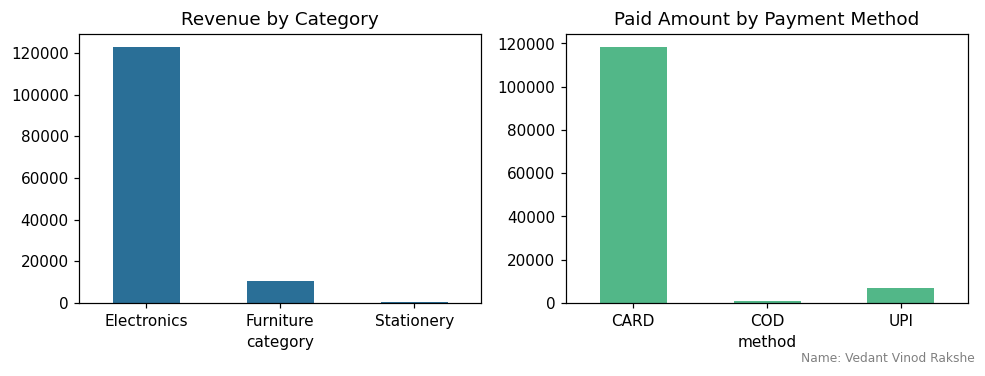

In [5]:
# ---- FINAL BUSINESS REPORT (historical + new data together)
print("Name: Vedant Vinod Rakshe")
print("1. REVENUE BY CATEGORY (cancelled orders excluded)")
rev = pd.read_sql("""SELECT category, COUNT(*) AS orders, SUM(order_total) AS revenue
                      FROM v_order_summary WHERE status <> 'CANCELLED'
                      GROUP BY category ORDER BY revenue DESC""", conn)
print(rev.to_string(index=False))

print("\n2. TOP CUSTOMERS BY ORDER VALUE")
top = pd.read_sql("""SELECT customer, COUNT(*) AS orders, SUM(order_total) AS total_value
                     FROM v_order_summary WHERE status <> 'CANCELLED'
                     GROUP BY customer ORDER BY total_value DESC, customer LIMIT 3""", conn)
print(top.to_string(index=False))

print("\n3. PAYMENT RECONCILIATION")
recon = pd.read_sql("""SELECT order_id, customer, order_total, paid_amount,
       CASE WHEN paid_amount = order_total THEN 'MATCHED'
            WHEN paid_amount = 0 THEN 'UNPAID' ELSE 'SHORT PAID' END AS payment_check
       FROM v_order_summary WHERE status <> 'CANCELLED' ORDER BY order_id""", conn)
print(recon.to_string(index=False))

methods = pd.read_sql("""SELECT method, SUM(amount) AS amount FROM payments
                        WHERE status = 'PAID' GROUP BY method""", conn)
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
rev.plot(kind="bar", x="category", y="revenue", ax=ax[0], legend=False, color="#2a6f97", rot=0)
ax[0].set_title("Revenue by Category")
methods.plot(kind="bar", x="method", y="amount", ax=ax[1], legend=False, color="#52b788", rot=0)
ax[1].set_title("Paid Amount by Payment Method")
plt.tight_layout()
plt.gcf().text(0.99, 0.005, "Name: Vedant Vinod Rakshe", ha="right", va="bottom", fontsize=8, color="gray")
plt.savefig("p9_ecommerce_report.png", dpi=110, bbox_inches="tight")
plt.show()
rev.to_csv("ecommerce_revenue_report.csv", index=False)

**Conclusion:** A complete pipeline from raw CSV data to a SQL database and report was built. The e-commerce ETL cleaned four related datasets, enforced referential integrity with foreign keys, rejected orphan and invalid records and reconciled payments with orders. New data was merged with the historical data using an upsert, so existing orders were updated and new orders were added without duplication.